# Notebook 01: Stochastic Processes

**Goal:** Build the mathematical foundation — finite state spaces, transition matrices, probability evolution.

By the end of this notebook you will be able to:
- Define a stochastic process over a finite state space
- Evolve a probability distribution through a sequence of transition matrices
- Recognize that classical Markov chains are the simplest case


In [7]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from isp.stochastic import StochasticProcess, make_markov_chain
from isp.visualization import plot_probability_evolution, plot_transition_matrix


## 1. Probability Distributions as Column Vectors

A state space has $n$ states. A probability distribution is a column vector
$\mathbf{p}$ with non-negative entries summing to 1.


In [8]:
# Two-state system: coin with bias 70/30
p = np.array([0.7, 0.3])
print(f"State |0⟩ probability: {p[0]}")
print(f"State |1⟩ probability: {p[1]}")
print(f"Normalization check (should be 1.0): {p.sum()}")


State |0⟩ probability: 0.7
State |1⟩ probability: 0.3
Normalization check (should be 1.0): 1.0


## 2. Transition Matrices

A transition matrix $T$ maps one distribution to the next:
$$\mathbf{p}(t_2) = T \cdot \mathbf{p}(t_1)$$

Each **column** of $T$ must sum to 1 — it's a probability distribution
over next states given a current state.


In [9]:
# Column-stochastic: T[i,j] = P(go to state i | currently in state j)
T = np.array([[0.8, 0.3],
              [0.2, 0.7]])

print("Column sums (must be 1.0):", T.sum(axis=0))

# Evolve p one step
p_next = T @ p
print(f"\np(t=0) = {p}")
print(f"p(t=1) = {p_next}")


Column sums (must be 1.0): [1. 1.]

p(t=0) = [0.7 0.3]
p(t=1) = [0.65 0.35]


In [10]:
# Build a StochasticProcess and evolve over multiple steps
T1 = np.array([[0.8, 0.3], [0.2, 0.7]])
T2 = np.array([[0.9, 0.1], [0.1, 0.9]])
T3 = np.array([[0.6, 0.5], [0.4, 0.5]])

proc = StochasticProcess(
    states=["heads", "tails"],
    transitions=[T1, T2, T3],
    times=[0.0, 1.0, 2.0, 3.0]
)

p0 = np.array([1.0, 0.0])  # start certain in "heads"
distributions = proc.evolve(p0)

for t, p in zip(proc.times, distributions):
    print(f"t={t:.1f}: P(heads)={p[0]:.3f}  P(tails)={p[1]:.3f}")


t=0.0: P(heads)=1.000  P(tails)=0.000
t=1.0: P(heads)=0.800  P(tails)=0.200
t=2.0: P(heads)=0.740  P(tails)=0.260
t=3.0: P(heads)=0.574  P(tails)=0.426


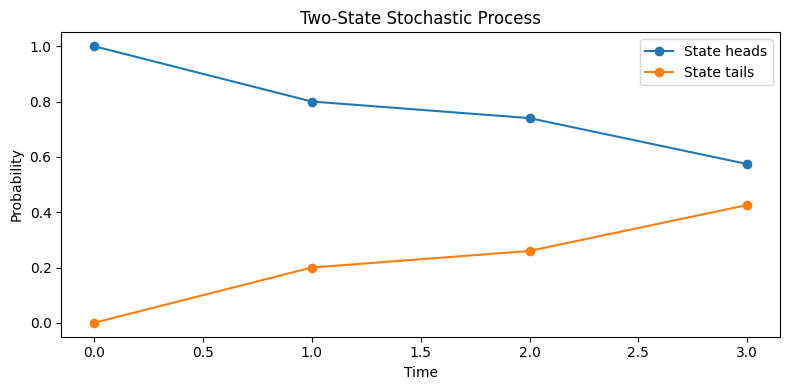

In [11]:
fig = plot_probability_evolution(proc, p0, title="Two-State Stochastic Process")
plt.tight_layout()
plt.show()


## 3. Continuous-Time Markov Chains

The simplest stochastic processes are continuous-time Markov chains,
generated by a **generator matrix** $L$:
$$T(t_2, t_1) = e^{L \cdot (t_2 - t_1)}$$

Generator convention: off-diagonal entries ≥ 0 (transition rates),
columns of $L$ sum to 0.


Column sums of L (must be 0): [0. 0.]


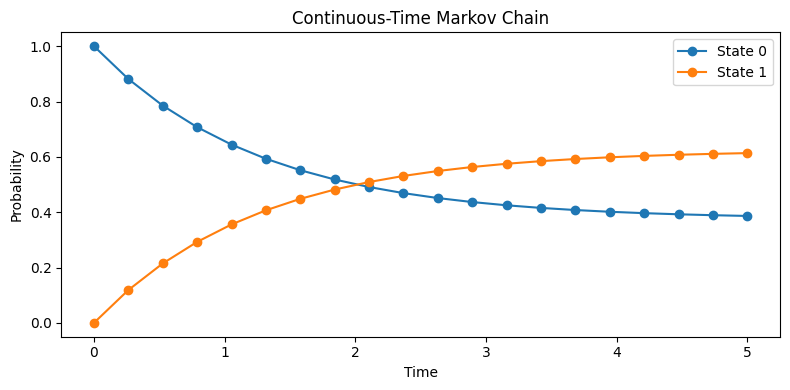

In [12]:
# Generator: rate 0.5 from state 0→1, rate 0.3 from state 1→0
L = np.array([[-0.5,  0.3],
              [ 0.5, -0.3]])

print("Column sums of L (must be 0):", L.sum(axis=0))

times = np.linspace(0, 5, 20).tolist()
markov = make_markov_chain(n_states=2, generator=L, times=times)

p0 = np.array([1.0, 0.0])
fig = plot_probability_evolution(markov, p0, title="Continuous-Time Markov Chain")
plt.tight_layout()
plt.show()


## Summary

- Stochastic states are column vectors; transition matrices left-multiply
- Every column of $T$ sums to 1 and has non-negative entries
- Continuous-time Markov chains are generated by $T(dt) = e^{L \cdot dt}$

**Next:** Notebook 02 examines the *divisibility* of these processes —
the mathematical property that will turn out to separate classical from quantum.
